
# makemore: part 3

In [21]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
import time
import numpy as np
import random
import torch.nn as nn

device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
   device = "mps:0"

print(f"Running on {device}")


Running on mps:0


In [22]:

### build the dataset
block_size = 1
T = 128
end_char = '_' 
batch_size = 512

DATA = "words"
DATA = "shakespaere"

if DATA == "words": # read in all the words
    with open("data/names.txt", "r") as f:
        words = f.readlines()
    words = [word.strip() for word in words]
    #random.seed(42)
    random.shuffle(words)
    if end_char in "".join(words): exit(f"the character '{end_char}' is already in the vocabulary")
    text = "_".join(words)
elif DATA == "claire":
    ########### LOAD FROM DATASET
    from datasets import load_dataset
    import re
    import unicodedata

    # Login using e.g. `huggingface-cli login` to access this dataset
    ds = load_dataset("OpenLLM-France/Claire-Dialogue-French-0.1")

    dialogues = [el['text'] for el in ds['train']]

    # Refomating
    to_remove_c = "µ"
    dialogues = [el.replace(to_remove_c, "") for el in dialogues]
    dialogues = [re.sub(r'\[.*?\] ', '', el) for el in dialogues]
    dialogues = [unicodedata.normalize('NFKD', el).encode('ascii', 'ignore').decode('utf-8') for el in dialogues]

    print(dialogues[0][:100])
    print(len(dialogues), "dialogues loaded")

    start_word = 0

    #### SPLITS
    for i in range (1000):
        if sum(len(w) + 1 for w in dialogues[start_word:start_word+i]) > 2000_000:
            words = dialogues[start_word:start_word+i]
            print( i,"cut at", i + start_word, "dialogues with ", sum(len(w) + 1 for w in words), "characters")
            start_word += i
            break
elif DATA == "shakespaere":
    with open("data/tiny_shakespeare.txt", "r") as f:
        text = f.read()

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string



class DataLoader:
    def __init__(self, data):
        self.data = data.to(device)
        self.reset()
        self.easy_mode = False

    def reset(self):
        self.batch_reset = True
        self.index = 0

        # create a random order for the indexes
        offset = random.randint(0, T)
        self.order = torch.randperm((len(self.data) - offset)//(batch_size*T)).to(device)
        self.order = self.order * batch_size * T + offset


    def get_batch(self):
        indexes = self.order[self.index]
        buf = self.data[indexes : indexes+batch_size*T+1]
        x = (buf[:-1]).view(batch_size, T) # inputs
        y = (buf[1:]).view(batch_size, T) # targets

        #self.index += batch_size * T
        #if self.index + batch_size * T + 1 > len(self.data):
        self.index += 1
        if self.index >= len(self.order):
            self.reset()
        return x, y


# Train and test splits
data = torch.tensor(encode(text))#, dtype=torch.long)
n = int(0.9*len(data)) # first 90% will be train, rest val
DLtr = DataLoader(data[:n])
DLte = DataLoader(data[n:])
print(f"vocab size {vocab_size} ,loaded {n} tokens : {n//batch_size} Time learning - {n//(batch_size * T)} batches of size {batch_size} and of length {T}")

# show first 5 examples
xb, yb = DLtr.get_batch()
print(f"ex : {decode(xb[0][:30].tolist())}")
for i in range(15,20):
    x = xb[:, i:i+block_size]
    y = yb[:, i+block_size - 1]
    #print(x, y)
    for b in range(2):
        print("X", i, ":", decode(x[b].tolist()), '-->', decode([y[b].tolist()]), end = "      \t\t")
    print()

for i in range(100):
    x, y = DLtr.get_batch()
    
    #print("X", i, ":", decode(x[0].tolist()), '-->', decode([y[0].tolist()]))
    assert x.shape == (batch_size,T), x.shape 
    assert y.shape == (batch_size,T), "mlkjqmlkdjf"
    assert (0 <= x).all() and  (x < vocab_size).all()
    assert (0 <= y).all() and (y < vocab_size).all()


DLtr.reset()


vocab size 65 ,loaded 1003854 tokens : 1960 Time learning - 15 batches of size 512 and of length 128
ex : 
Desire to breed by me. Here's
X 15 : d -->        		X 15 :   --> r      		
X 16 :   --> b      		X 16 : r --> i      		
X 17 : b --> y      		X 17 : i --> s      		
X 18 : y -->        		X 18 : s --> e      		
X 19 :   --> m      		X 19 : e --> s      		


# MODEL

In [23]:
def myprint(t, name):
    print(f"{name:<10} : {tuple(t.shape)} ")#: {t[:1].tolist()}")


torch.set_default_dtype(torch.float32)


class MyModule(nn.Module):
    debug = False
    def states(self):return []
    def reset_state(self): return "default reset"
    def to(self, device):

        states =  self.states()
        for i in range(len(states)):
            if states[i] is None: continue # Ensure parameter exists
            states[i].data = states[i].data.to(device)  # Update the data in-place
        return super().to(device)



def call(mod, fn, *args, on_myself=True):
    out = []
    if on_myself:
        out =  [fn(mod, *args) if callable(fn) else f"{fn} is not callable"]
    for c in mod.children():
        out.extend(call(c, fn, *args))
    return out
        

# -----------------------------------------------------------------------------------------------

class Embedding(MyModule): # for each vocab index, look up the corresponding vector in a table
    def __init__(self, num_embeddings, embedding_dim):
        super().__init__()
        self.weight = nn.Parameter(torch.randn((num_embeddings, embedding_dim)))
        self.IX = torch.zeros(32)
        
    def __call__(self, IX): # IX : (Batch, T(Time))
        self.IX = IX
        self.out = self.weight[IX] 
        return self.out # (B, T, C : channel)
    
    def backward(self, delta, x=None):
        IX = self.IX
        flattened_indices = IX.view(-1)  # Shape: (Batch * T)
        flattened_delta = delta.view(-1, delta.shape[-1])  # Shape: (Batch * T, Embedding_dim)
        self.weight.grad.index_add_(0, flattened_indices, flattened_delta)
        return self.weight.grad
    
# PYTORCHIFYING -----------
class Linear(MyModule):
    
    def __init__(self, fan_in, fan_out, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.randn((fan_in, fan_out)) * (2/(fan_in+fan_out)) )
        self.bias = nn.Parameter(torch.zeros(fan_out)) if bias else None
    
    def __call__(self, x):
        self.x = x
        self.out = x @ self.weight
        if self.bias is not None:        
            self.out += self.bias
        return self.out
    
    def backward(self, delta, x=None, grad=True): # delta : (batch, T, fan_out)
        if x is None: x = self.x

        if grad:
            if self.bias is not None:
                self.bias.grad += delta.sum(dim=tuple(range(delta.ndim - 1)))

            x_reshaped = x.view(-1, x.shape[-1])  # Shape: (B * T, D)
            delta_reshaped = delta.view(-1, delta.shape[-1])  # Shape: (B * T, C)
            self.weight.grad += x_reshaped.T @ delta_reshaped  # Shape: (fan_in, fan_out)

        x_grad = delta @ self.weight.T # x grad : (batch, fan_in)
        return x_grad
    

class LinearBlocks(MyModule):
    def __init__(self, fan_in, fan_out, n_blocks=1, bias=True):
        super().__init__()
        # my wheights is (K, fan_in, fan_out) where K is the number of blocks
        self.weight = nn.Parameter(torch.randn((n_blocks, fan_in, fan_out)) * (2/(fan_in+fan_out)))
        self.bias = nn.Parameter(torch.zeros(fan_out)) if bias else None
        self.n_blocks = n_blocks
    
    def __call__(self, x): # x : (batch, ..., fan_in)
        self.x = x # x-> (B, ...., K, fan_in//K)
        
        # Broadcast mat2 to match input's batch size
        #mat2_expanded = mat2.unsqueeze(0).expand(batch_size, -1, -1, -1)  # Shape: (10, 5, 8, 6)
        # Perform batch matrix multiplication
        #res_matmul = torch.matmul(input.unsqueeze(-2), mat2_expanded).squeeze(-2)

        x = x.reshape(*x.shape[:-1], self.n_blocks, -1) # (B, ..., K, fan_in//K)
        out = torch.einsum('...bi,bio->...bo', x, self.weight) # (B, ..., K, fan_out//K)
        self.out = out.reshape(*out.shape[:-2], -1) # (B, ..., fan_out)

        #self.out = x @ self.weight
        if self.bias is not None:        
            self.out += self.bias
        return self.out
    
    def backward(self, delta, x=None): # delta : (batch, ..., fan_out)
        if x is None: x = self.x

        if self.bias is not None:
            self.bias.grad += delta.sum(dim=tuple(range(delta.ndim - 1)))

        #x_reshaped = x.view(-1, x.shape[-1])  # Shape: (B * T, D) (B + ..., fan_in)
        #delta_reshaped = delta.view(-1, delta.shape[-1])  # Shape: (B * T, C)
        #self.weight.grad += x_reshaped.T @ delta_reshaped  # Shape: (fan_in, fan_out) 
        # (K, fan_in//K, fan_out//K)
        x = x.reshape(*x.shape[:-1], self.n_blocks, -1) # (B, ..., K, fan_in//K)
        delta = delta.view(*delta.shape[:-1], self.n_blocks, -1) # (B, ..., K, fan_out//K)
        self.weight.grad += torch.einsum('...bi,...bo->bio', x, delta)#.view(self.weight.shape) # (K, fan_in//K, fan_out//K)

        #x_grad = delta @ self.weight.T # x grad : (... ,batch, fan_in)
        x_grad = torch.einsum('...bo,bio->...bi', delta, self.weight) # (B, ..., K, fan_in//K)
        x_grad = x_grad.reshape(*x_grad.shape[:-2], -1) # (B, ..., fan_in)

        return x_grad

    
# -----------------------------------------------------------------------------------------------
class LayerNorm(MyModule):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps # for numerical stability
        self.dim = dim
        self.gamma = nn.Parameter(torch.ones(dim)) # (dim)
        self.beta = nn.Parameter(torch.zeros(dim)) # (dim)

    
    def __call__(self, x):
        self.compute_mms(x)
        self.out = self.gamma * (self.mu * self.sigma_inv) + self.beta
        return self.out
    
    def compute_mms(self, x):
        # calculate the forward pass
        self.xmean = x.mean(dim=-1, keepdim=True)
        self.mu = x - self.xmean
        xvar = x.var(dim=-1, unbiased=False, keepdim=True)
        self.sigma_inv = torch.sqrt(xvar + self.eps)**(-1) # normalize to unit variance
    
    
    def backward(self, delta, x=None, grad=True): # delta : (batch, T ..., dim)
        if x is not None:
            self.compute_mms(x)
        mu, sigma_inv, gamma = self.mu, self.sigma_inv, self.gamma

        if grad:
            self.beta.grad += delta.sum(dim=tuple(range(delta.ndim - 1)))
            self.gamma.grad += (delta * mu * sigma_inv).sum(dim=tuple(range(delta.ndim - 1)))  # sum over batch : (dim)  
        
        # b:batch, h:hidden
        delta = (
            delta*gamma.unsqueeze(0) * sigma_inv
            - 1/self.dim * (torch.einsum('...h,h,...i->...', [delta, gamma, sigma_inv]).unsqueeze(-1) 
                 + mu * torch.einsum('...h,h,...h,...i->...', [delta, gamma, mu, sigma_inv**(3)]).unsqueeze(-1))
        )
        return delta # delta : (batch, dim)

  
# -----------------------------------------------------------------------------------------------

class Tanh(MyModule):
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def backward(self, delta, x=None, grad=True):
        if x is not None:
            self.__call__(x)
        return delta * (1 - self.out**2)

# -----------------------------------------------------------------------------------------------

class Flatten(MyModule):
    def __init__(self, input_shape, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.input_shape = input_shape

    def __call__(self, x):
        self.out = x.view(x.shape[0], -1)
        return self.out
    def backward(self, delta, x=None):
        return delta.view(self.input_shape)

# -----------------------------------------------------------------------------------------------

# Split and sum Module : split the input into the split_shape -> run the layers with the split input -> sum the output
class SplitSum(MyModule): # n > 1
    def __init__(self, layers, split_shape, save_x=False):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.save_x = save_x
        self.split_shape = split_shape

    def __call__(self, x):  # (B,T, sum indim)
        split = x.split(self.split_shape, dim=-1)
        return sum(layer(s) for s, layer in zip(split, self.layers)) # (B,T, sum outdim)

    def backward(self, delta, x=None):
        if x is not None:
            split = x.split(self.split_shape, dim=-1)
            return torch.cat([layer.backward(delta, x=s) for s, layer in zip(split, self.layers)], dim=-1)

        return torch.cat([layer.backward(delta, x=x) for layer in self.layers], dim=-1)
    
# -----------------------------------------------------------------------------------------------

class Concat(MyModule):  # 1 -> n
    def __init__(self, layers, split_shape, save_x=False):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.save_x = save_x
        self.split_shape = split_shape

    def __call__(self, x_cat): # (B,..., Sum indim)
        lst = [layer(x_cat) for layer in self.layers]
        return torch.cat(lst, dim=-1) # (B,T, Sum outdim)

    def backward(self, delta, x=None): # delta : (B,... , Sum outdim) -> (B,..., Sum indim
        ds = delta.split(self.split_shape, dim=-1)
        out =  [layer.backward(ds[i], x=x) for i, layer in enumerate(self.layers)]
        out = torch.sum(torch.stack(out), dim=0)
        return out 
    
# -----------------------------------------------------------------------------------------------

# model class for looping over a layer
# this class is STATEFUL, it keeps track of the hidden state
class Loop(MyModule):
    def __init__(self, input_dim, output_dim, hidden_dim, n_blocks=1):
        super().__init__()

        layers = [ Linear(input_dim + hidden_dim, hidden_dim + output_dim, bias=True), 
                     LayerNorm(hidden_dim + output_dim), Tanh()]
        
        l_io = Linear(input_dim, input_dim, bias=True)
        l_ho = Linear(hidden_dim, output_dim, bias=False)
        l_oh = Linear(output_dim, hidden_dim, bias=True)
        #l_hh = Linear(hidden_dim, hidden_dim, bias=False)

        assert hidden_dim % n_blocks == 0, "hidden dim must be even"
        l_hh = LinearBlocks(hidden_dim//n_blocks, hidden_dim//n_blocks, n_blocks=n_blocks, bias=False)

        
        l_ih_o = SplitSum(layers=[l_io, l_ho], split_shape=(input_dim , hidden_dim))
        l_ih_h = SplitSum(layers=[l_oh, l_hh], split_shape=(output_dim, hidden_dim))

        layers = [Concat(layers=[ l_ih_o, l_ih_h], split_shape=(output_dim, hidden_dim)),
                    LayerNorm(hidden_dim + output_dim), Tanh()]
        
        self.layer = Sequential(layers=layers, save_x=True, input_dim=(input_dim + hidden_dim))

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.hidden_dim = hidden_dim

        self.initial_h = nn.Parameter(torch.randn(1, hidden_dim) * 0.1)  # initialize hidden state to zeros

        self.no_direct_input = False
        self.no_loop = False
        self.device = None
        self.reset_state()

    def reset_state(self):
        #backward state
        self.dgrad = torch.zeros(batch_size, self.hidden_dim, device=self.device)
        # initialize hidden state : (different hidden state for each example in the batch)
        self.h = self.initial_h.expand(batch_size, -1) # (batch, hidden_dim)

    def __call__(self, x): # x : (batch, T, input_dim) and h : (1, hidden_dim)
        # LOOP over all the times
        y = torch.zeros(batch_size, T, self.output_dim, device=self.device)
        for t in range(T): # loop over all the times
            xt = x[:,t]

            out = self.layer(torch.cat([xt, self.h], dim=-1))
            yt, oh = out.split([self.output_dim, self.hidden_dim], dim=-1)
            self.h = oh# + self.h 
            if self.no_loop: self.h = torch.zeros_like(self.h)
            y[:,t] = yt
        return y

    def backward(self, delta, x=None): # (B, T, out dim)
        T = delta.shape[1]
        delta_out = torch.zeros(batch_size, T, self.input_dim, device=self.device)
        for t in range(T-1, -1, -1):
            delta_t = delta[:,t]
            out = self.layer.backward(torch.cat([delta_t, self.dgrad], dim=-1))
            delta_out_t, self.dgrad = out.split([self.input_dim, self.hidden_dim], dim=-1)

            #self.dgrad = self.dgrad + torch.ones_like(self.dgrad) # because we did f1(h) = h + f2(h) --> f1'(h) = 1 + f2'(h)
            delta_out[:,t] = delta_out_t
            
        self.initial_h.grad += self.dgrad.sum(dim=0)
        return delta_out

    
    def states(self):
        return [self.h, self.dgrad]

# -----------------------------------------------------------------------------------------------

class Sequential(MyModule):
    def __init__(self, layers, save_x=False, input_dim=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.layers = nn.ModuleList(layers)
        self.save_x = save_x
        self.input_dim = input_dim
        self.device = None

        self.update_BT_size()
    
    def reset_state(self):
        if self.save_x:
            self.t = 0

    def update_BT_size(self):
        if not self.save_x: return
        self.t = 0
        self.saved_x = []
        ## INPUT : (B,T,inp) -> (B,inp) -> (B, inp + hidden) 
        xt = torch.zeros(batch_size, self.input_dim, device=self.device)
        for l in self.layers:
            self.saved_x.append(torch.zeros(xt.shape[0], T, *xt.shape[1:], device=self.device))
            xt = l(xt)
    
    def __call__(self, x):
        for i, layer in enumerate(self.layers):
            if self.save_x and self.training:
                self.saved_x[i][:,self.t] = x
            x = layer(x)
        if self.save_x and self.training:
            self.t += 1
        return x
    
    def backward(self, delta, x = None, *args): 
        if self.save_x:
            self.t -= 1
            assert self.t >= 0, "t is negative"
        for i, layer in reversed(list(enumerate(self.layers))):
            #print(delta.device, ' brefore' , layer.__class__.__name__ )
            if self.save_x:
                x = self.saved_x[i][:,self.t]
            delta = layer.backward(delta, x=x, *args)
        return delta
    

  
# -----------------------------------------------------------------------------------------------
        
# class to wrap all the layers modules
class Model(Sequential):
    def __init__(self, layers):
        super().__init__(layers)
    
    def self_call(self, fn_name, *args):
        def function(x):
            if not hasattr(x, fn_name):
                return f"{x.__class__.__name__} don't have '{fn_name}'"
            method = getattr(x, fn_name)
            if not callable(method):
                return f"{fn_name} not callable on {x.__class__.__name__}"
            return method(*args), f"{fn_name} called on {x.__class__.__name__}"
            
        return call(self, function, on_myself=False)
    
    def reset_state(self):
        return self.self_call("reset_state")

    def set_var(self, var_name, value):
        return call(self, lambda x: value if setattr(x, var_name, value) is None else "not none")# if hasattr(x, var_name) else f"{var_name} is not an attribute")
    
    def get_var(self, var_name):
        return call(self, lambda x: getattr(x, var_name) if hasattr(x, var_name) else None)

def backward_cross_entropy(_y, _Yb): # cross entropy loss backward pass
    dy = F.softmax(_y, dim=-1)
    dy[torch.arange(_y.size(0)), _Yb] -= 1
    dy /= batch_size
    return dy

model = Model([                # (B, T)
    Embedding(vocab_size, n_embd),  # (B, T, C)
    Loop(input_dim=n_embd, output_dim=n_out_hidden, hidden_dim=n_hidden, n_blocks=n_blocks), 
    # loop of T : (B, t  C) -> (B, t, C_h)
    Linear(n_out_hidden, vocab_size) # (B, T, Vocab size)
])



In [24]:
import torch

# Example dimensions
batch_size = 10
b = 5  # blocks
i = 8  # input size
o = 6  # output size

# Input tensors
input = torch.randn(batch_size, b, i)
mat2 = torch.randn(b, i, o)

# Broadcast mat2 to match input's batch size
mat2_expanded = mat2.unsqueeze(0).expand(batch_size, -1, -1, -1)  # Shape: (10, 5, 8, 6)
# Perform batch matrix multiplication
res_matmul = torch.matmul(input.unsqueeze(-2), mat2_expanded).squeeze(-2)

# Verify correctness
res_einsum = torch.einsum('...bi,bio->...bo', input, mat2)
assert torch.allclose(res_einsum, res_matmul), "Results differ!"

print(f"{mat2.shape} {mat2_expanded.shape} {res_matmul.shape}")

print("Optimized implementation works correctly!")

torch.Size([5, 8, 6]) torch.Size([10, 5, 8, 6]) torch.Size([10, 5, 6])
Optimized implementation works correctly!


In [25]:

n_embd = 40 # the dimensionality of the character embedding vectors
n_out_hidden = n_embd


n_hidden = 2048#256 # the number of neurons in the hidden layer of the MLP
n_blocks = 16

total_steps, train_index, train_time = 0, 0, 0
lossi = [] # store loss values

CMP = False
torch.set_grad_enabled(CMP)
torch.manual_seed(42)

LOOP = True

if LOOP:
    model = Model([                # (B, T)
        Embedding(vocab_size, n_embd),  # (B, T, C)
        Loop(input_dim=n_embd, output_dim=n_out_hidden, hidden_dim=n_hidden, n_blocks=n_blocks), 
        # loop of T : (B, t  C) -> (B, t, C_h)
        Linear(n_out_hidden, vocab_size) # (B, T, Vocab size)
    ])
else:
    model = Model([
        Embedding(vocab_size, n_embd), 
        Linear(n_embd , n_hidden, bias=True), LayerNorm(n_hidden), Tanh(),  
        Linear(n_hidden, vocab_size)
    ])
# with torch.no_grad():
#     last layer: make less confident
#     model.layers[-1].weight *= 0.1
#     model.layers[-1].bias *= 0.1
#   all other layers: apply gain
#   for layer in model.layers[:-1]:
#     if isinstance(layer, Linear):
#       layer.weight *= 0.5 #* 5/3

model.set_var("device", device)
model = model.to(device)

def show_states(model):
    states = model.get_var("h")
    for s in states:
        if s is not None:
            # # scatter with a different color for each example in the batch
            # for i in range(s.shape[0]):
            #     plt.scatter(range(s.shape[1]), s[i].detach().cpu().numpy(), label=f'Example {i}', cmap='viridis', alpha=0.5, s=10)

            values = s.detach().cpu().numpy()#[:, :100]
            mean = values.mean(axis=0)
            std = values.std(axis=0)

            #for i in range(values.shape[0]):
            #    plt.scatter(range(values.shape[-1]), values[i], s=1)


            #plt.plot(mean)
            plt.scatter(range(values.shape[-1]), mean, s=1)
            plt.show()

            # print the hash value
            print(f"mean : {mean.mean()} std : {std.mean()} hash : {hash(tuple(mean))}")


if CMP:
    for p in model.parameters():
        p.requires_grad = True

print(f"Total parameters : {sum(p.nelement() for p in model.parameters())}")
#print(model)
for name, l in model.named_modules():
    print(f"{l.__class__.__name__:<30} : {name:<30} :   size : {sum(p.nelement() for p in l.parameters())} ({l.device if hasattr(l, 'device') else 'no device'})")
for name, p in model.named_parameters():
    print(f"{name:<30} :  {str(tuple(p.shape)):<20}  size : {p.nelement():<10}  ({p.device})")






Total parameters : 441161
Model                          :                                :   size : 441161 (mps:0)
ModuleList                     : layers                         :   size : 441161 (mps:0)
Embedding                      : layers.0                       :   size : 2600 (mps:0)
Loop                           : layers.1                       :   size : 435896 (mps:0)
Sequential                     : layers.1.layer                 :   size : 433848 (mps:0)
ModuleList                     : layers.1.layer.layers          :   size : 433848 (mps:0)
Concat                         : layers.1.layer.layers.0        :   size : 429672 (mps:0)
ModuleList                     : layers.1.layer.layers.0.layers :   size : 429672 (mps:0)
SplitSum                       : layers.1.layer.layers.0.layers.0 :   size : 83560 (mps:0)
ModuleList                     : layers.1.layer.layers.0.layers.0.layers :   size : 83560 (mps:0)
Linear                         : layers.1.layer.layers.0.layers.0.l

In [40]:
# same optimization as last time
steps = 1_00
batch_size = 1
T = 256

base_lr = 1e-3

model.train()
model.set_var("no_direct_input", False)
model.set_var("no_loop", False)
model.self_call("update_BT_size")

for p in model.parameters():
    p.grad = torch.zeros_like(p)


total_steps = train_index
steps -= (total_steps + steps) % steps
steps = max(10, steps)
total_steps += steps
start_time = time.time()

print(f"training on {device} for {steps} steps of {batch_size} batches of {T} tokens -- {steps * (batch_size * T)} tokens -- {steps//(batch_size * T)} epochs")

for i in range(steps):
    # minibatch construct : sample a random subset of the data
    Xb, targets = DLtr.get_batch() # (B, T)
    # if DLtr.batch_reset:
    #     DLtr.batch_reset = False
    model.reset_state()
    
    # forward pass
    y = model(Xb) # y : (B, T, Vocab size)
    
    targets = targets.view(-1) # (B * T)
    y = y.view(-1, vocab_size) # (B * T, vacab)vocab_size
    loss = F.cross_entropy(y, targets) # y needs to be (B * T, C)


    ############# backward pass ################
    # zero all the gradients in the model
    for p in model.parameters():
        p.grad.zero_()

    dy = backward_cross_entropy(y, targets)
    dy = dy.view(batch_size, T, -1) # (B, T, C)
    delta = model.backward(dy)

    # if CMP: 
    #     # zero all the gradients in the model
    #     for p in model.parameters():
    #         p.grad = None
    #     y.retain_grad() 
    #     loss.backward() # backpropagate the error
    #     cmp("dy", dy, y.grad, only_errors=True)

    ##################################################

    # update
    lr = base_lr if train_index < 3500 else base_lr / 10 # step learning rate decay    
    
    for name, p in model.named_parameters():
        p.data += -lr * p.grad
        #if CMP: cmp(name, p.grad, g, only_errors=True)

    # modif layers.1.layer.layers.0.weight : set to 0 the blocks(input_dim:, ouput_dim:)
    
    # loop_w = model.layers[1].layer.layers[0].weight
    # block_count = 4
    # input_dim=n_embd
    # output_dim=n_out_hidden
    # for j in range(block_count):
    #     ixs = input_dim + (j    *n_hidden) // block_count
    #     ixe = input_dim + ((j+1)*n_hidden) // block_count
    #     iys = output_dim +(j    *n_hidden) // block_count
    #     iye = output_dim +((j+1)*n_hidden) // block_count
    #     # only keep the weight in loop_w[ixs:ixe, iys, iye]
    #     loop_w.data[input_dim:ixs, iys:iye] = 0
    #     loop_w.data[ixe:, iys:iye] = 0
    

    # track stats
    lossi.append(loss.log10().item())
    #print(f"{i}/{steps} : {loss.item():.4f} - {10**loss.item():.4f}  ({time.time() - start_time:.0f}s)", end = "\r")
    if i % (steps//10) == 0: # print every once in a while
        dt = time.time() - start_time
        start_time = time.time()
        train_time += dt
        processed_tokens = (steps//10) * batch_size * T
        average_loss = sum(lossi[-(steps//10):])/len(lossi[-(steps//10):])
        print(f'{train_index:7d}/{total_steps:7d}:  {average_loss:.4f} - {10**average_loss:.4f}  ({train_time:.0f}s : +{int(dt):3d}s)  {processed_tokens / (dt*1e3):.0f} k tok/s  {(steps//10) *60 / (dt):.0f} step/min ')

        #show_states(model)
    train_index += 1

print(f"Training time: {train_time:.0f} seconds")



training on mps:0 for 99 steps of 1 batches of 256 tokens -- 25344 tokens -- 0 epochs
    401/    500:  0.5200 - 3.3111  (256s : +  0s)  3 k tok/s  598 step/min 
    410/    500:  0.5283 - 3.3755  (263s : +  7s)  0 k tok/s  75 step/min 
    419/    500:  0.5213 - 3.3209  (270s : +  7s)  0 k tok/s  76 step/min 
    428/    500:  0.5134 - 3.2612  (277s : +  6s)  0 k tok/s  77 step/min 
    437/    500:  0.5134 - 3.2610  (284s : +  6s)  0 k tok/s  78 step/min 
    446/    500:  0.5235 - 3.3383  (291s : +  6s)  0 k tok/s  78 step/min 
    455/    500:  0.5287 - 3.3784  (298s : +  6s)  0 k tok/s  78 step/min 
    464/    500:  0.5152 - 3.2749  (305s : +  6s)  0 k tok/s  78 step/min 
    473/    500:  0.5279 - 3.3725  (312s : +  6s)  0 k tok/s  78 step/min 
    482/    500:  0.5170 - 3.2886  (319s : +  6s)  0 k tok/s  77 step/min 
    491/    500:  0.5216 - 3.3233  (326s : +  6s)  0 k tok/s  78 step/min 
Training time: 326 seconds


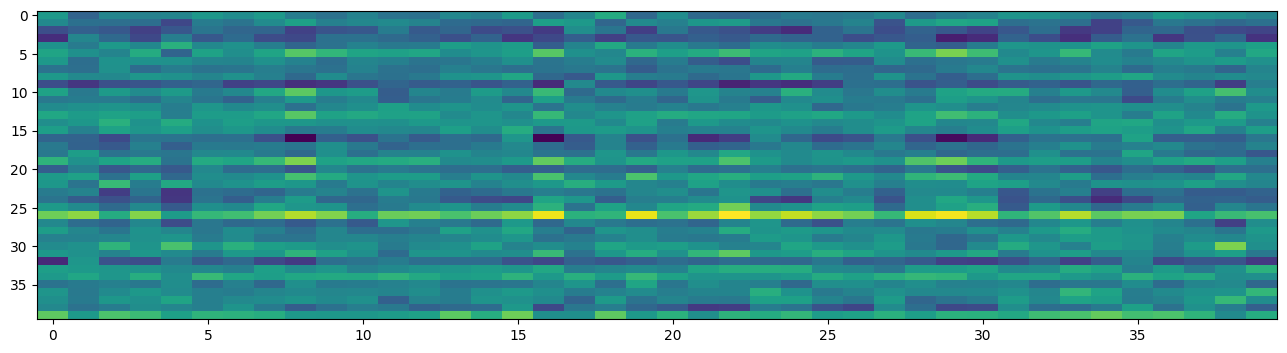

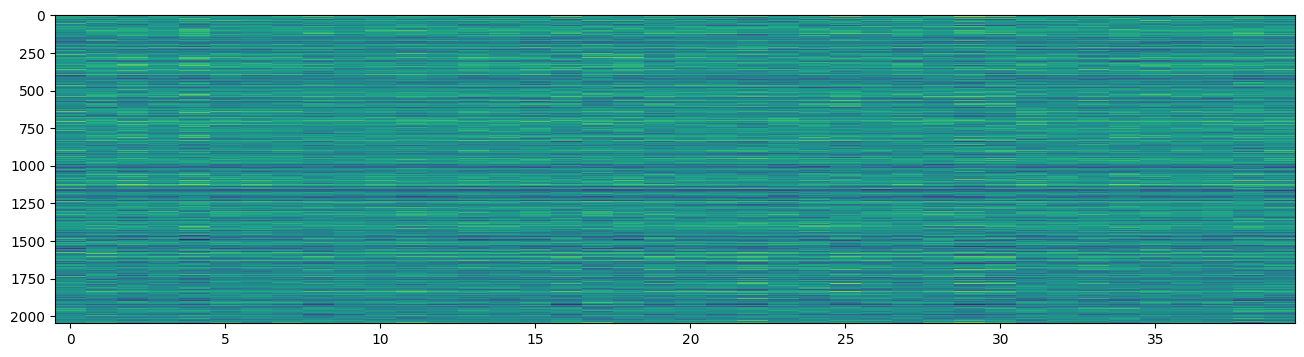

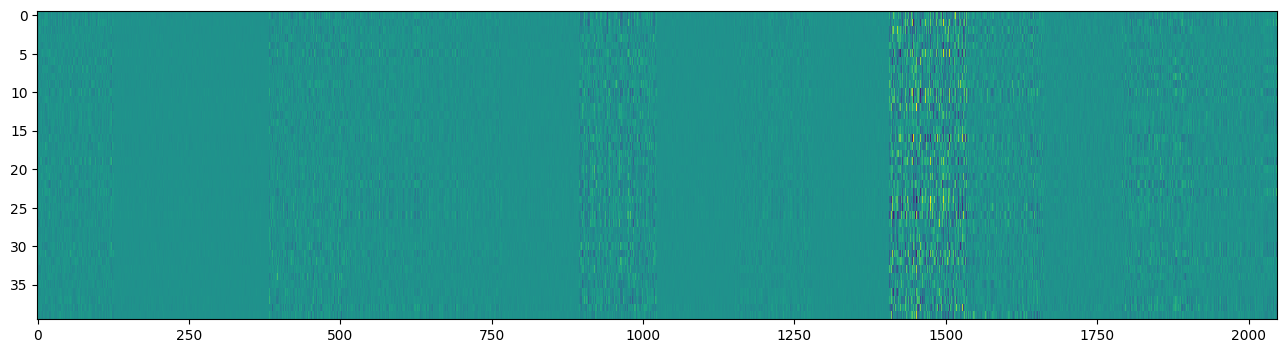

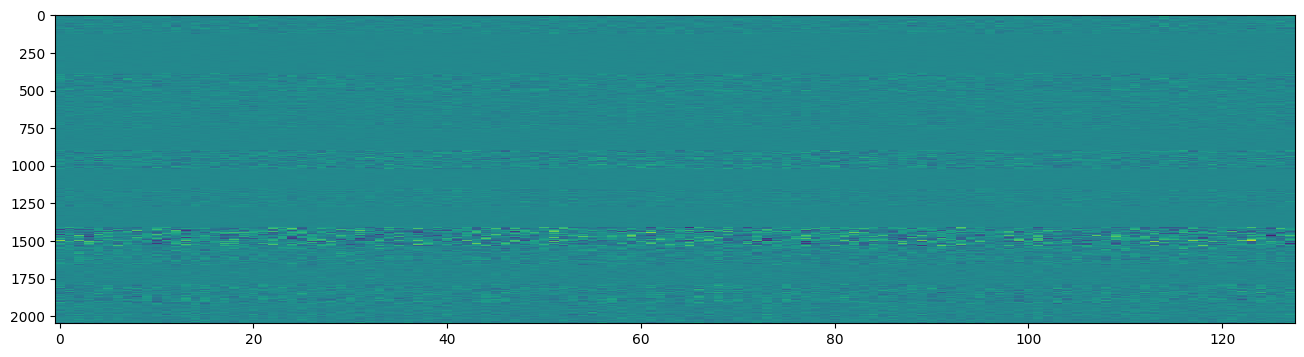

abs mean : 0.4260847270488739 abs std : 0.3525604009628296, 100.0 % non zero weights  20% threshold: 0.20274536311626434
abs mean : 0.1250525563955307 abs std : 0.09619133919477463, 100.0 % non zero weights  20% threshold: 0.059111569076776505
abs mean : 11.590121269226074 abs std : 17.897422790527344, 100.0 % non zero weights  20% threshold: 2.466362237930298
abs mean : 3.612623453140259 abs std : 5.096479415893555, 100.0 % non zero weights  20% threshold: 0.7815002202987671


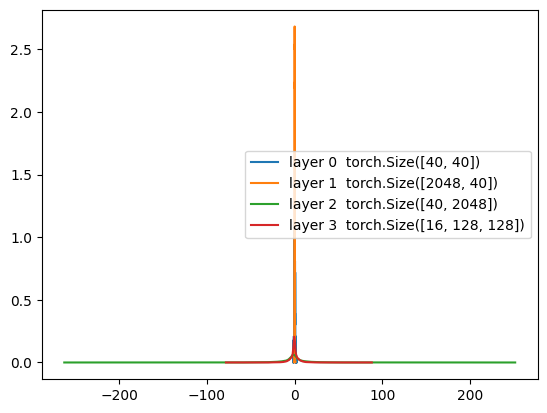

In [27]:

def find_loop(layer):
    if layer.__class__.__name__ == "SplitSum":
        for l in layer.layers:
            global layers
            if l.__class__.__name__ == "Linear" or l.__class__.__name__ == "LinearBlocks":
                layers.append(l)

    if layer.__class__.__name__ == "Loop":
        if layer.layer.layers[0].__class__.__name__ == "Linear":
            layers.append()

layers = []
call(model, find_loop);

for layer in layers:
    loop_w = layer.weight
    if loop_w.dim() == 3:
        loop_w = loop_w.view(-1, loop_w.shape[-1])
    threshold = np.percentile(loop_w.abs().cpu().numpy(), 30)
    # fugure of size 4*10
    plt.figure(figsize=(16, 4))
    plt.imshow(loop_w.cpu().numpy(), aspect='auto', interpolation='none') #  > threshold
    plt.show()

for layer in layers:
    w = layer.weight
    threshold = np.percentile(w.abs().cpu().numpy(), 30)
    print(f"abs mean : {w.abs().mean().item()} abs std : {w.abs().std().item()}, {w.count_nonzero()/ w.nelement() *100} % non zero weights  20% threshold: {threshold}")
    #plt.plot(np.histogram(w.flatten().cpu().numpy(), bins=200)[0]) 
    # plot the histogram with the correct x axis
    h = np.histogram(w.flatten().cpu().numpy(), bins=200, density=True)
    plt.plot(h[1][:-1], h[0])

plt.legend([f"layer {i}  {l.weight.shape}" for i, l in enumerate(layers)])

w = torch.cat([layer.weight.flatten() for layer in layers], dim=0)
threshold = np.percentile(w.abs().cpu().numpy(), 30)
# plt.axvline(x=-threshold, color='r', linestyle='--')
# plt.axvline(x=threshold, color='r', linestyle='--')




# 100 steps, 85s (Batch: 128, block: 1, lr: 0.0003, hidden: 2048) : 3.8966464042663573
# train loss : 3.8893   	 acc 15.3% 	 prob 2.2%     (log:0.5898714290473639)
# test  loss : 3.8966  	 acc 15.0% 	 prob 2.2%
Overfitting : 0.007346534729003817


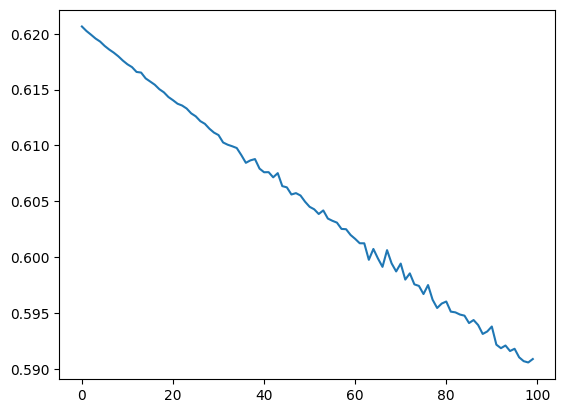

In [28]:


model.eval()

#  Evaluate the model
@torch.no_grad()  # Disable gradient tracking
def split_loss_and_accuracy(DL, n_iteration=30):
    avg_loss = 0
    correct_predictions = 0
    total_predictions = 0
    avg_correct_prob = 0
    
    for i in range(n_iteration):
        # Get the input and target sequences
        x, y = DL.get_batch()  # Fetch data batch
        model.reset_state()

        # Forward pass through the model
        x = model(x)  # Output logits
        x = x.view(-1, vocab_size)  # Reshape logits for loss computation
        y = y.view(-1)  # Flatten targets

        # Compute loss
        avg_loss += F.cross_entropy(x, y, reduction='mean').item()

        # Compute accuracy
        predictions = torch.argmax(x, dim=1)  # Predicted class indices
        correct_predictions += (predictions == y).sum().item()  # Count correct predictions
        total_predictions += y.size(0)  # Count total predictions
        
        proba = F.softmax(x, dim=1)
        correct_probs = proba[torch.arange(y.size(0)), y]  # Correct class probabilities
        avg_correct_prob += correct_probs.mean().item()

    avg_loss /= n_iteration  # Average the loss over iterations
    accuracy = correct_predictions / total_predictions  # Compute accuracy
    avg_correct_prob /= n_iteration
    return avg_loss, accuracy, avg_correct_prob

trl, tracc, tr_prob = split_loss_and_accuracy(DLtr)
test, teacc, te_prob = split_loss_and_accuracy(DLte)

print(f"# {total_steps} steps, {train_time:.0f}s (Batch: {batch_size}, block: {block_size}, lr: {base_lr}, hidden: {n_hidden}) : {test}")
print(f"# train loss : {trl:.4f}   \t acc {tracc * 100:.1f}% \t prob {tr_prob * 100:.1f}%     (log:{np.log10(trl)})")
print(f"# test  loss : {test:0.4f}  \t acc {teacc * 100:.1f}% \t prob {te_prob * 100:.1f}%")


print(f"Overfitting : {test - trl}")
if test - trl > 0.1:
    print("\033[91mModel is overfitting\033[0m")

spliter = 10**int(np.log10(len(lossi))-2)

plt.plot(torch.tensor(lossi[:len(lossi)//spliter*spliter]).view(-1, spliter).mean(1));


# 1 letter

# LOOP  
# # 13000 steps, 708s (Batch: 32, block: 1, lr: 0.01, hidden: 64) : 2.0660481452941895
# train loss : 2.0372254848480225      (log:0.30903910038242466)  
#  test  loss : 2.0660
# 2000 steps, 420s (Batch: 32, block: 1, lr: 0.001, hidden: 256) : 2.0285587986310323
#  train loss : 1.9258   	 acc 45.7% 	 prob 29.6%     (log:0.2846129310450921)
# test  loss : 2.0286  	 acc 42.0% 	 prob 28.2%
## ON shakespaere
# 5700 steps, 972s (Batch: 64, block: 1, lr: 1e-05, hidden: 256) : 1.9928557395935058
# train loss : 1.8798   	 acc 47.4% 	 prob 30.6%     (log:0.27412079568294734)
# test  loss : 1.9929  	 acc 43.3% 	 prob 28.8%

# 6000 steps, 1769s (Batch: 256, block: 1, lr: 1e-05, hidden: 2048) : 2.0588078180948894
# train loss : 1.9326   	 acc 47.1% 	 prob 29.2%     (log:0.2861399360175299)
# test  loss : 2.0588  	 acc 42.9% 	 prob 27.3%


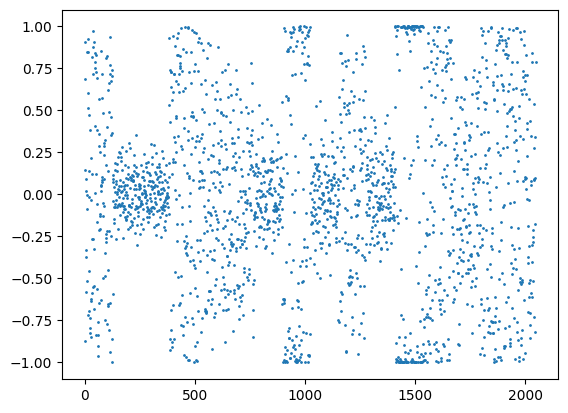

mean : -0.008241070434451103 std : 0.0 hash : -250842040243983006


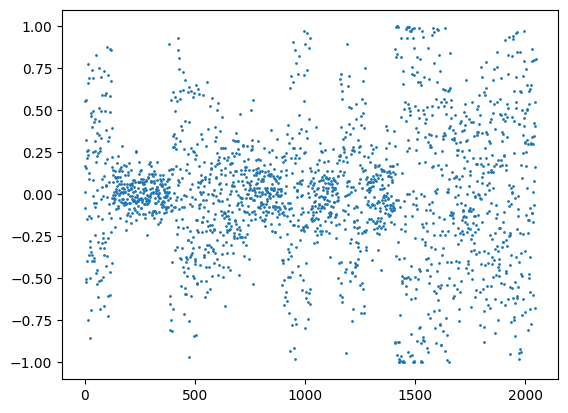

mean : 0.0004291695076972246 std : 0.2935571074485779 hash : 4438103572582574110


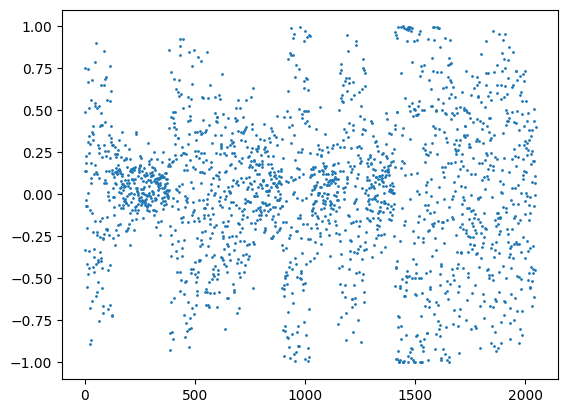

mean : 0.009556412696838379 std : 0.26344865560531616 hash : -1225791849930327701


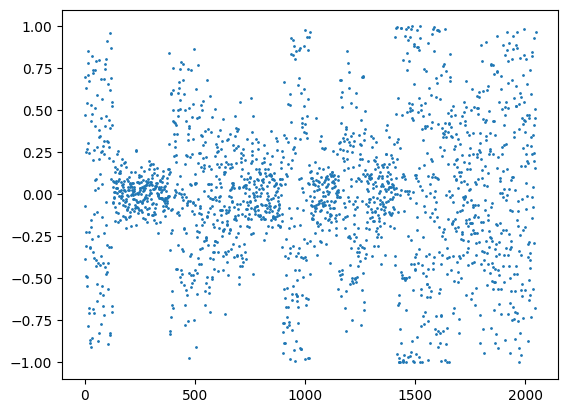

mean : -0.0032492061145603657 std : 0.2615671455860138 hash : -8175244643331435181


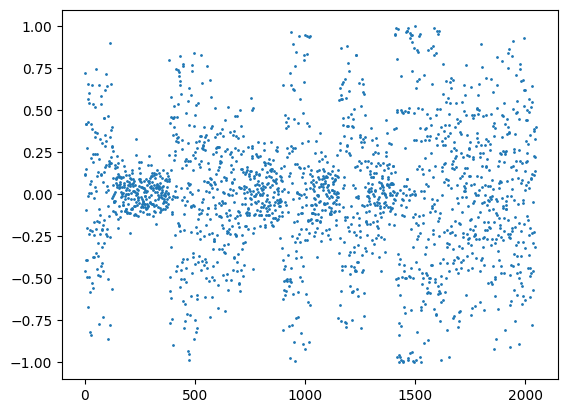

mean : 0.004256770946085453 std : 0.30141791701316833 hash : -7576873736944863332


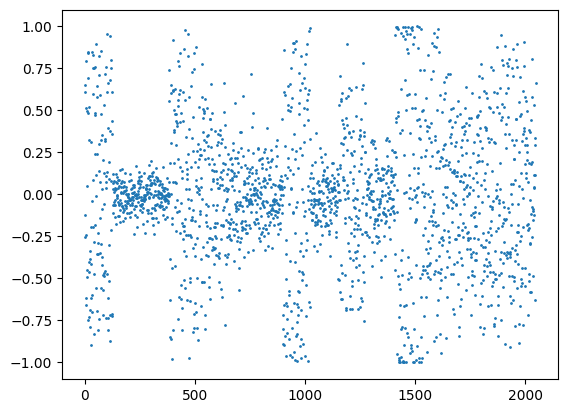

mean : -0.010059289634227753 std : 0.26552140712738037 hash : 7377941830449466854


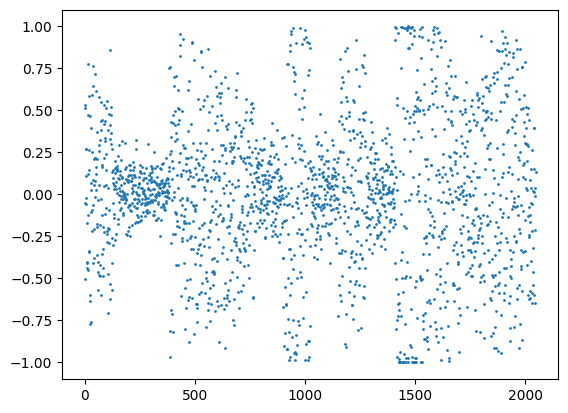

mean : 0.0017963923746719956 std : 0.22428345680236816 hash : -8212663560376563275


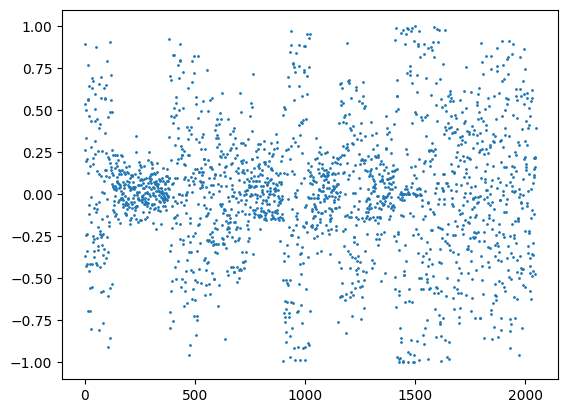

mean : 0.0061318399384617805 std : 0.29098281264305115 hash : 7017102721539091563


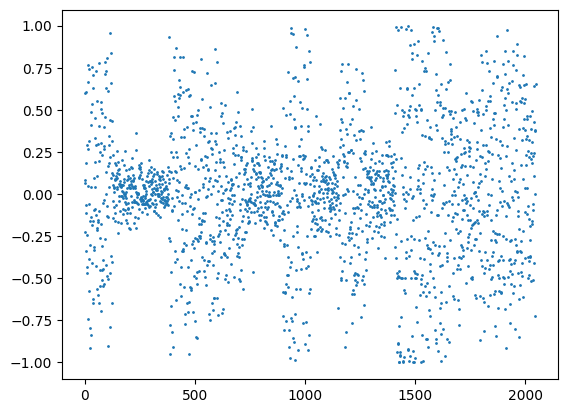

mean : -0.003209678689017892 std : 0.2846832573413849 hash : -6233169213158720609


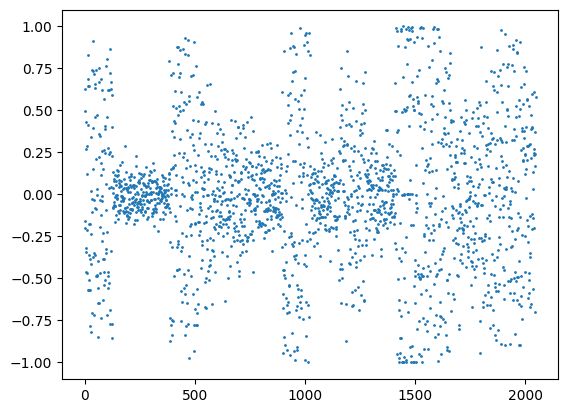

mean : -0.00830297451466322 std : 0.2710418999195099 hash : 959227864232179352


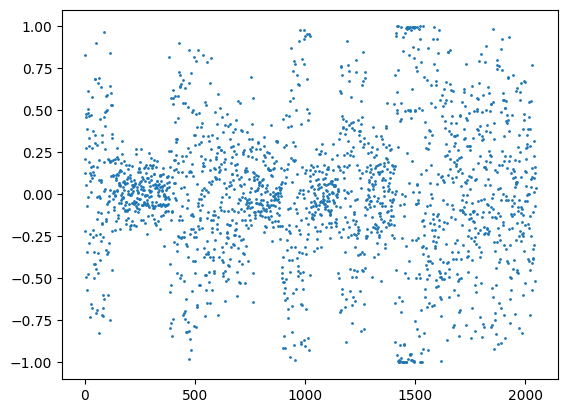

mean : 0.002916123019531369 std : 0.2584473788738251 hash : 2468846364211514279


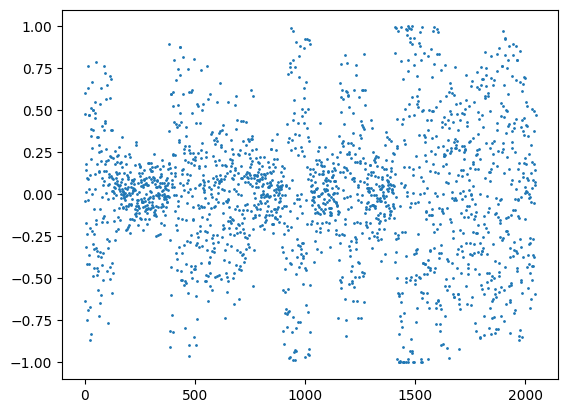

mean : 0.00256451522000134 std : 0.2673983573913574 hash : -8352101137953214758


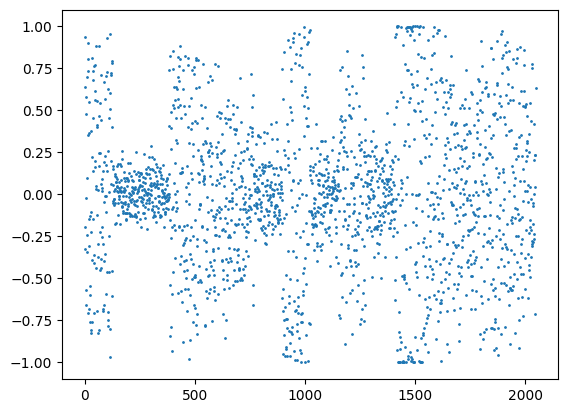

mean : -0.006507540121674538 std : 0.20564255118370056 hash : 6983648973321811300


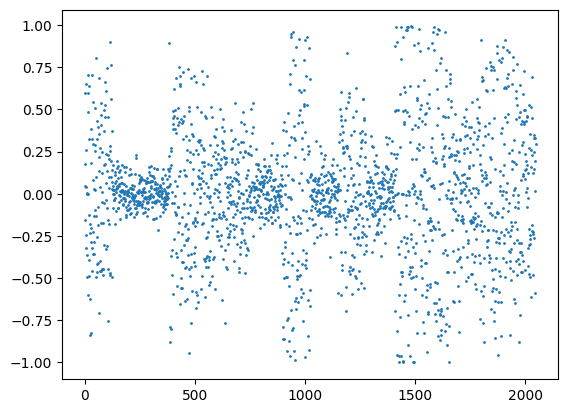

mean : 9.51552065089345e-05 std : 0.2794955372810364 hash : 3272630345402575784
65 tokens : MENENIUS:
The senators of Rome are this good belly,-QWIvoqo-PoeWa
-------------   INPUT:'MENENIUS:
The senators of Rome are this good belly,
OUT:'-QWIvoqo-PoeWa'
CORRECT:'n every offic
----
INPUT:'MENENIUS:
The senators of Rome are this good belly,
OUT:'YEmvFtpN-ftmSc'
CORRECT:'ave thy duty;
----
INPUT:'MENENIUS:
The senators of Rome are this good belly,
OUT:'gp?$ecavtGH'iL'
CORRECT:'ath.

CURTIS:
----
INPUT:'MENENIUS:
The senators of Rome are this good belly,
OUT:' rlaRw LcIY,Z,'
CORRECT:'e news.

GRUM


In [29]:
# sample from the model

model.eval()
model.reset_state()
g = torch.Generator(device=device).manual_seed(2147483647 + 10)
T = 1
n_gen_tok = 64
batch_size = 4

model.self_call("update_BT_size")

def generate_from(model, x, max_tokens=1000):
    # x : (B,T)
    model.reset_state()

    for i in range(max_tokens):
        inp = x[:,i:i+1]
        y = model(inp).view(-1, vocab_size)
        # print(y.shape)
        if i+1 >= x.shape[1]:
            show_states(model)
            probs = F.softmax(y, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g)
            x = torch.cat([x, ix], dim = 1)
    return x

T = n_gen_tok
x, y = DLte.get_batch()#[0][:, 0:1]
T = 1
x = x[:, :n_gen_tok // 2]
x = torch.asarray([encode("MENENIUS:\nThe senators of Rome are this good belly,") for _ in range(batch_size)]).to(device)

out = generate_from(model, x, max_tokens=n_gen_tok)

for txt in out[:1]:
    txt = txt.tolist()
    print( f"{len(txt)} tokens :", decode(txt)) #.replace(end_char, " "))

print(f"-------------  ", '\n----\n'.join([ ("INPUT:'" +  decode(x[i].tolist()) + 
                               "\nOUT:'" + decode(out[i, x.shape[1]:].tolist()) + 
                               "'\nCORRECT:'" + decode(y[i, x.shape[1]:].tolist())) for i in range(4)] ))
    # mean : 0.000860393512994051 std : 0.0 hash : 8810571046427816516
    # mean : 0.0008603953756392002 std : 0.0 hash : -4059708961267572039


In [30]:

def cmp(s, a, b, only_errors=False):
    app = torch.allclose(a, b, atol=1e-7)
    if only_errors and app: return
    ex = torch.all(a == b).item()
    maxdiff = (a - b).abs().max().item()
    app_color = '\033[92m' if app else '\033[91m'
    exact_color = '\033[92m' if ex else '\033[91m'
    print(f'{s:15s} | {exact_color}exact: {str(ex):5s} {app_color}| approximate: {str(app):5s} | maxdiff: {maxdiff}\033[0m')
    if (a == torch.zeros_like(a)).all() or (b == torch.zeros_like(b)).all():
        print(f"WARNING : ZEROS : a {a.tolist()} and b {b.tolist()}")

